# Datos listos para redactar: China–España

Comparación principal 1990–2023 y contabilidad del crecimiento 1960–2023. Esta es la capa gold del informe: indicadores, tablas y gráficos con fórmulas y notas. Las entregas silver anteriores se conservan. La guía completa está en `output/preparacion_informe/GUIA_PARA_REDACTAR.md`.

Las alternativas permiten analizar evolución y estructura. No acreditan equivalencia exacta de todos los conceptos; dos bloques siguen parciales: rentas completas e input-output bilateral.

In [1]:
from pathlib import Path
import json
import polars as pl
from IPython.display import display, Image, Markdown
ROOT=Path.cwd() if (Path.cwd()/'datos').exists() else Path.cwd().parent
OUT=ROOT/'output/preparacion_informe'
GOLD=ROOT/'datos/gold/informe'
d=pl.read_parquet(GOLD/'indicadores.parquet')
catalogue=pl.read_csv(GOLD/'diccionario.csv',infer_schema_length=None)
registry=pl.read_csv(OUT/'catalogo_resultados.csv',infer_schema_length=None)
display(json.loads((OUT/'resumen.json').read_text()))
display(pl.read_csv(OUT/'estado_requisitos.csv').select('id','title','status','artifacts'))

{'indicators': 259,
 'observations': 15759,
 'figures': 38,
 'tables': 21,
 'reused': 8,
 'requirements': 27,
 'requirements_status': [{'status': 'ADAPTADO', 'len': 17},
  {'status': 'PREPARADO', 'len': 8},
  {'status': 'PARCIAL', 'len': 2}],
 'comparison_period': [1990, 2023],
 'growth_period': [1960, 2023],
 'exact_data_complete': False,
 'report_written': False,
 'missing_values_filled': False,
 'source_files_modified': False}

id,title,status,artifacts
str,str,str,str
"""2A.production""","""Producción, consumos intermedi…","""ADAPTADO""","""2A.1;2A.3_ratios"""
"""2A.gdp""","""PIB nominal y real""","""ADAPTADO""","""2A.3_pib"""
"""2B.levels""","""Demanda real""","""ADAPTADO""","""2B.1"""
"""2B.shares""","""Composición y medias de demand…","""ADAPTADO""","""2B.3_shares;2B.T1"""
"""2B.growth""","""Tasas de crecimiento de demand…","""PREPARADO""","""2B.3_growth"""
…,…,…,…
"""6.2""","""Crecimiento medio PIB por habi…","""ADAPTADO""","""6.T2"""
"""6.3""","""PIB por subperíodos""","""ADAPTADO""","""6.T3"""
"""6.4""","""PIB por habitante por subperío…","""ADAPTADO""","""6.T4"""


## Crecimiento: mismos subperiodos y dos medidas distintas

Las tasas compuestas (CAGR) describen variaciones acumulativas. Las contribuciones de capital, empleo y residuo se suman al crecimiento logarítmico anualizado. Las tablas 6.3–6.4 y 7.1 comparten subperiodos. El residuo de Solow incluye todo lo no explicado por estos dos inputs; no es una medición exclusiva de tecnología.

In [2]:
display(pl.read_csv(GOLD/'tablas/6.T3.csv'))
display(pl.read_csv(GOLD/'tablas/7.T1.csv'))

country,start,end,years,cagr_pct
str,i64,i64,i64,f64
"""CHN""",1960,1989,29,6.31989
"""CHN""",1989,2000,11,9.819259
"""CHN""",2000,2008,8,10.687159
"""CHN""",2008,2019,11,7.825823
"""CHN""",2019,2023,4,4.694044
"""ESP""",1960,1989,29,4.774259
"""ESP""",1989,2000,11,2.847431
"""ESP""",2000,2008,8,3.073349
"""ESP""",2008,2019,11,0.619542


country,start,end,years,gdp_log_pp,gdp_pc_log_pp,gdp_cagr_pct,gdp_pc_cagr_pct,capital_log_pp,employment_log_pp,population_log_pp,capital_contribution_pp,labor_contribution_pp,solow_residual_pp,alpha
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""CHN""",1960,1989,29,6.12822,4.224858,6.31989,4.315375,6.560309,2.613246,1.903362,2.18677,1.742164,2.199286,0.333333
"""CHN""",1989,2000,11,9.366573,8.339811,9.819259,8.697446,9.432194,1.29657,1.026762,3.144065,0.86438,5.358128,0.333333
"""CHN""",2000,2008,8,10.153765,9.536756,10.687159,10.006312,11.370104,0.662401,0.617009,3.790035,0.441601,5.922129,0.333333
"""CHN""",2008,2019,11,7.534699,6.943016,7.825823,7.18972,10.85697,0.0306,0.591683,3.61899,0.0204,3.895309,0.333333
"""CHN""",2019,2023,4,4.587205,4.603638,4.694044,4.711251,7.457044,-0.479451,-0.016433,2.485681,-0.319634,2.421157,0.333333
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ESP""",2000,2008,8,3.027068,1.531018,3.073349,1.542798,3.821361,2.952881,1.49605,1.273787,1.968588,-0.215307,0.333333
"""ESP""",2008,2019,11,0.617631,0.38468,0.619542,0.38542,1.253341,-0.350677,0.232951,0.41778,-0.233784,0.433635,0.333333
"""ESP""",2019,2023,4,0.879908,0.630049,0.883791,0.632038,1.191455,0.685109,0.249859,0.397152,0.456739,0.026017,0.333333


## Demanda y productividad

Los componentes reales se estudian como índices y tasas de la misma edición PWT NA. Las participaciones son nominales. La productividad usa PIB y empleo PWT; las horas son totales, calculadas como ocupados por horas medias. Los gráficos conservan paneles separados para ambos países.

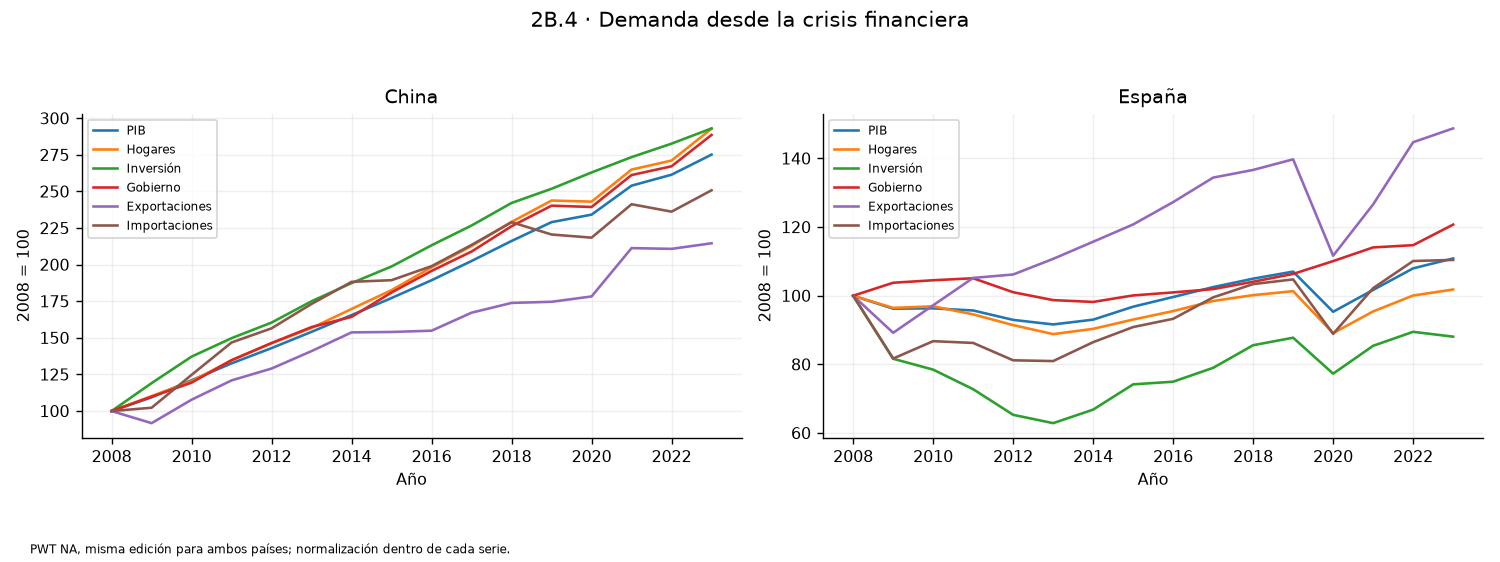

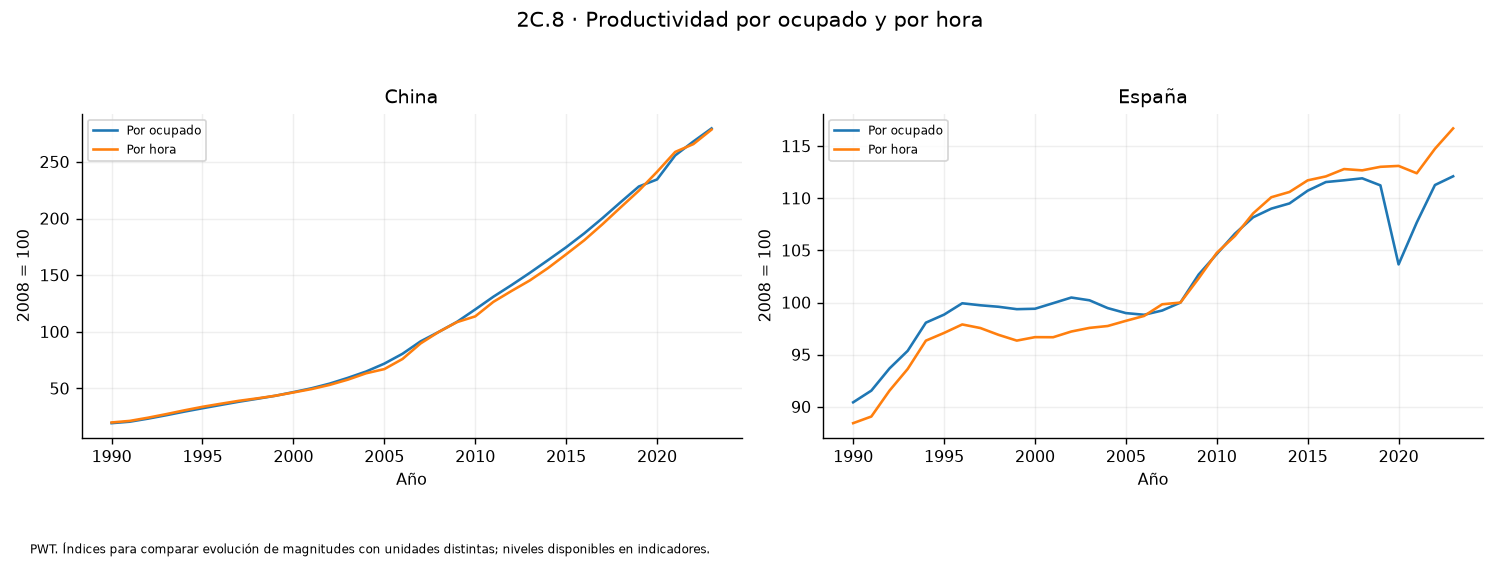

country,start,end,metric,n,actual_first,actual_last,mean,sample_years,note
str,i64,i64,str,i64,i64,i64,f64,str,str
"""CHN""",1990,2023,"""share_c""",34,1990,2023,40.91112,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""CHN""",1990,2023,"""share_i""",34,1990,2023,41.170778,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""CHN""",1990,2023,"""share_g""",34,1990,2023,15.198519,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""CHN""",1990,2023,"""share_x""",34,1990,2023,22.903204,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""CHN""",1990,2023,"""share_m""",34,1990,2023,19.976371,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""ESP""",1990,2023,"""share_c""",34,1990,2023,58.835427,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""ESP""",1990,2023,"""share_i""",34,1990,2023,23.467791,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""ESP""",1990,2023,"""share_g""",34,1990,2023,18.333327,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"
"""ESP""",1990,2023,"""share_x""",34,1990,2023,27.456631,"""1990;1991;1992;1993;1994;1995;…","""Medias de cocientes nominales,…"


In [3]:
for id in ['2B.4','2C.8']:
    display(Image(filename=str(OUT/'figuras'/(id+'.png'))))
display(pl.read_csv(GOLD/'tablas/2B.T1.csv').filter((pl.col('start')==1990)&(pl.col('end')==2023)))

## Muestras comparables para los estadísticos

Cada correlación usa exactamente los mismos años para China y España dentro del par y ventana. Las muestras pueden diferir entre variables. Se muestra n y se conserva la lista de años y cada observación utilizada. Las existencias usan cambios de un índice del flujo, no tasas porcentuales; por ello se omite su desviación relativa frente al PIB.

In [4]:
display(pl.read_csv(GOLD/'tablas/2B.T3.csv').select('country','window_start','window_end','metric','n','mean','correlation','relative_sd'))
display(pl.read_csv(GOLD/'tablas/2C.T2.csv').filter(pl.col('metric')=='change_inventories').select('country','window_start','window_end','n','actual_last','correlation','relative_sd','note'))

country,window_start,window_end,metric,n,mean,correlation,relative_sd
str,i64,i64,str,i64,f64,f64,f64
"""CHN""",1996,2019,"""growth_na_q_gdp""",24,8.956412,1.0,1.0
"""ESP""",1996,2019,"""growth_na_q_gdp""",24,2.161361,1.0,1.0
"""CHN""",1996,2019,"""growth_na_q_c""",24,8.571449,0.461299,0.915841
"""ESP""",1996,2019,"""growth_na_q_c""",24,1.889205,0.96534,1.112928
"""CHN""",1996,2019,"""growth_na_q_i""",24,9.81756,0.604864,2.370351
…,…,…,…,…,…,…,…
"""ESP""",1996,2023,"""growth_na_q_g""",28,2.456347,0.243598,0.663323
"""CHN""",1996,2023,"""growth_na_q_x""",28,9.888375,0.615327,3.255179
"""ESP""",1996,2023,"""growth_na_q_x""",28,4.399858,0.821447,1.991321


country,window_start,window_end,n,actual_last,correlation,relative_sd,note
str,i64,i64,i64,i64,f64,f64,str
"""CHN""",1996,2019,24,2019,0.453012,null,"""VE: correlación de cambios anu…"
"""ESP""",1996,2019,24,2019,-0.483638,null,"""VE: correlación de cambios anu…"
"""CHN""",1996,2023,24,2019,0.453012,null,"""VE: correlación de cambios anu…"
"""ESP""",1996,2023,24,2019,-0.483638,null,"""VE: correlación de cambios anu…"


## Remuneración por ocupado y mercado laboral

El indicador docente D1/ocupados no es salario por asalariado. Se combina D1 nacional con empleo PWT y se utiliza el deflactor del PIB nacional. La comparación laboral principal emplea modelos OIT/WDI en ambos países; registros y encuestas nacionales mantienen sus coberturas propias.

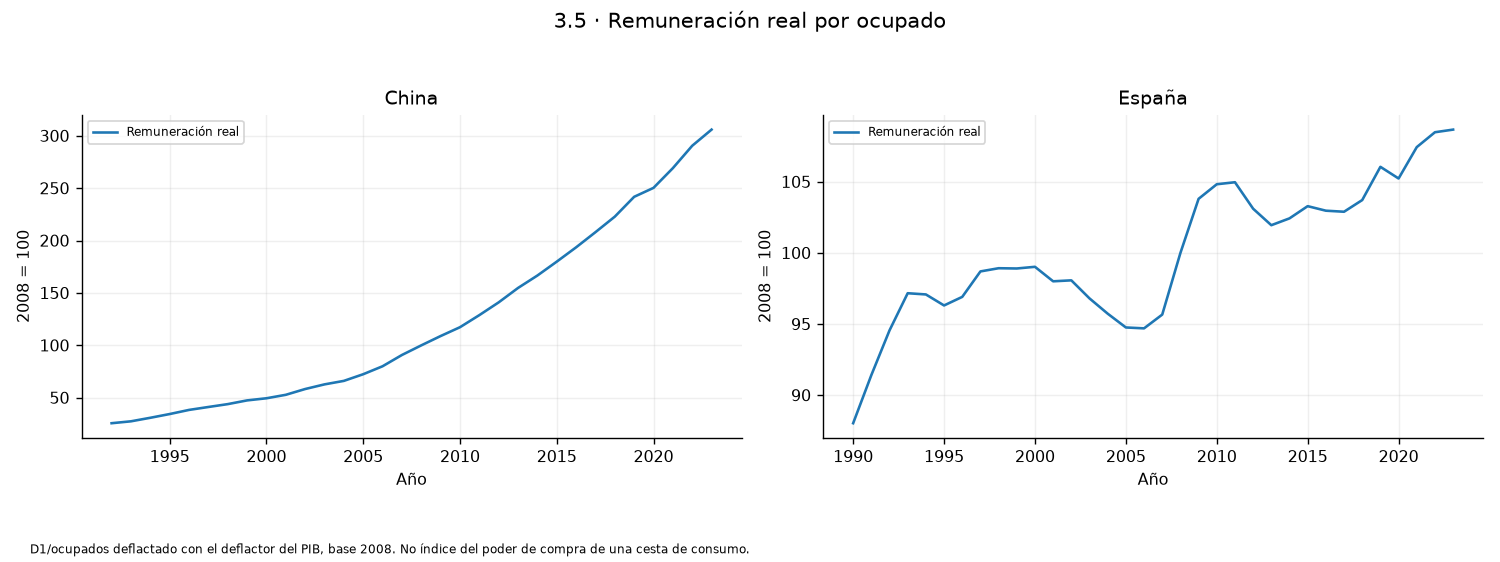

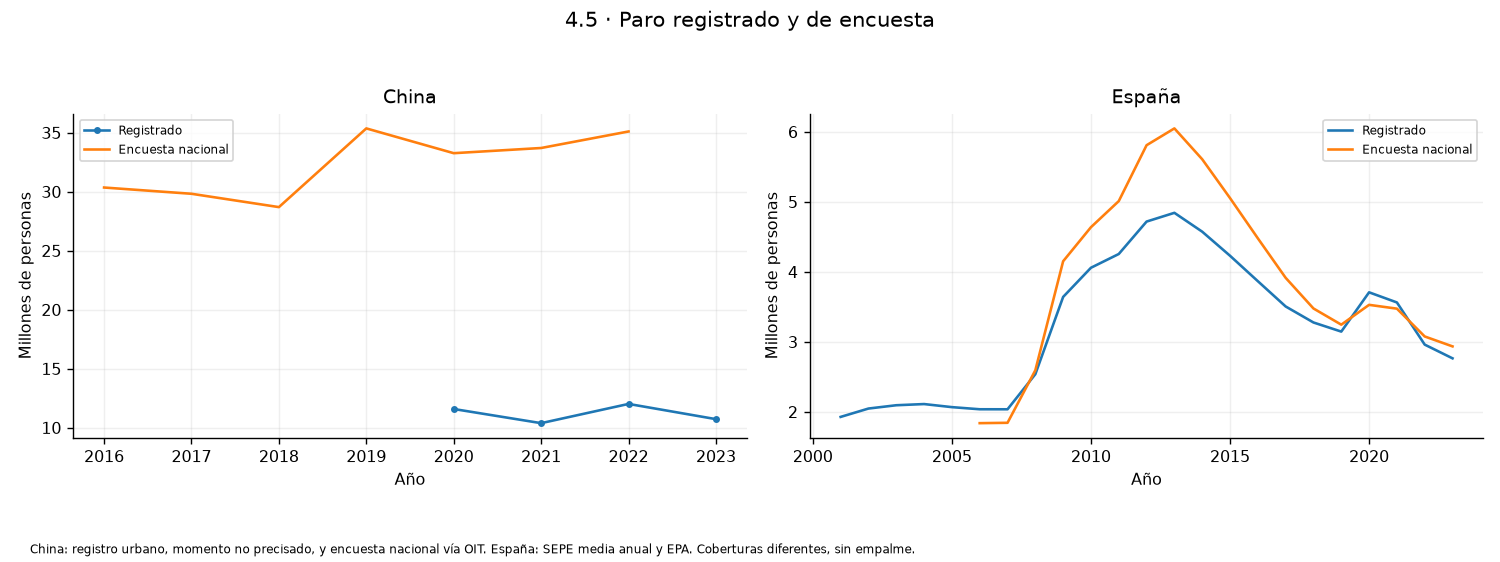

country,window_start,window_end,metric,n,correlation
str,i64,i64,str,i64,f64
"""CHN""",1996,2019,"""growth_unemployment_model""",24,0.033289
"""ESP""",1996,2019,"""growth_unemployment_model""",24,0.581623
"""CHN""",1996,2019,"""growth_employment_model""",24,-0.055778
"""ESP""",1996,2019,"""growth_employment_model""",24,-0.31119
"""CHN""",1996,2023,"""growth_unemployment_model""",28,0.038765
"""ESP""",1996,2023,"""growth_unemployment_model""",28,0.521668
"""CHN""",1996,2023,"""growth_employment_model""",28,0.172223
"""ESP""",1996,2023,"""growth_employment_model""",28,-0.214222


In [5]:
for id in ['3.5','4.5']:
    display(Image(filename=str(OUT/'figuras'/(id+'.png'))))
display(pl.read_csv(GOLD/'tablas/3.T4.csv').select('country','window_start','window_end','metric','n','correlation'))

## Limitaciones que hay que llevar al texto

Las notas distinguen restricciones de acceso, falta de cobertura y diferencias económicas. Las aproximaciones aceptadas deben acompañarse de su interpretación; no es necesario enumerar detalles técnicos que no afectan a las conclusiones. La matriz española IO y las referencias históricas docentes adicionales siguen pendientes de incorporación. El borrador Typst anterior aún no refleja esta capa de datos.

In [6]:
display(pl.read_csv(OUT/'limitaciones.csv'))
display(registry.filter(pl.col('status')=='PARCIAL').select('id','title','note','missing'))
display(Markdown('El índice visual completo está en **output/preparacion_informe/index.html**. Cada figura conserva sus datos exportados en **datos/gold/informe/figuras_datos/**.'))

id,topic,problem,decision,artifacts
str,str,str,str,str
"""L01""","""Producción e intermedios""","""China solo tiene un año IO 202…","""Figura estructural y cocientes…","""2A.1;2A.3_ratios"""
"""L02""","""Demanda real""","""Las escalas y bases monetarias…","""Índices dentro de cada serie, …","""2B.1;2B.4;2B.T3"""
"""L03""","""Consumo de capital fijo""","""Falta CCF real oficial chino c…","""CCF real aproximado ΣDc/Np; se…","""2C.1;2C.4;2C.T1;2C.T2"""
"""L04""","""Existencias""","""FMI/IFS real termina en 2019 y…","""Escala con |valor 2008|; cambi…","""2C.1;2C.T2"""
"""L05""","""Rentas""","""China: D2 distribuido coincide…","""Coste de factores aproximado; …","""2D.1;2D.3;2D.T1"""
…,…,…,…,…
"""L08""","""Mercado laboral""","""Encuestas, modelos OIT y regis…","""Bloque común modelizado WDI pa…","""4.3;4.4;4.5;4.T1"""
"""L09""","""Muestras estadísticas""","""Las coberturas por fuente y va…","""Intersección de años de ambos …","""2B.T3;2C.T2;2C.T3;3.T1;3.T2;3.…"
"""L10""","""Input-output España""","""No se ha incorporado una matri…","""Tabla china preparada. Compara…","""2D.T2"""


id,title,note,missing
str,str,str,str
"""2D.T2""","""Input-output en tres sectores""","""China 2023: flujos en unidad n…","""Matriz española equivalente no…"
"""2D.1""","""Rentas y producto nominal""","""China: excedente incluye renta…",""""""


El índice visual completo está en **output/preparacion_informe/index.html**. Cada figura conserva sus datos exportados en **datos/gold/informe/figuras_datos/**.